## Algorithme Apriori

### Définition

Algorithme de machine learning non supervisé utilisé pour l’apprentissage des règles d’association.  
L’apprentissage des règles d’association est une technique de data mining qui identifie les modèles fréquents, les connexions et les dépendances entre différents groupes d’éléments appelés jeux d’éléments dans les données.  
Parmi les cas d’utilisation courants, on trouve les systèmes de prédiction et de recommandation de maladies, comme l’analyse du panier d’achat pour les plateformes de commerce électronique

https://www.ibm.com/fr-fr/think/topics/apriori-algorithm

## Cours // exemple "à la mano"

#### Question : Quels produits sont achetés ensemble, plus souvent que le hasard ne le prévoirait ?  

Méthode ⇒ règles d'association, calculées avec l'algorithme Apriori sur les tickets de caisse.

C'est une méthode non supervisée : on ne prédit pas une variable, on cherche des motifs dans les données.  
Résulat attendu ⇒ règles du type : si un client achète A et B, alors il achète souvent C. Afin de déterminer par exemple : le rangement des rayons et implantation des produits, des promotions croisées, recommandations sur un site marchand, composition de packs...

### Les données

#### Vocabulaire

Transaction = un achat : l'ensemble des produits d'un ticket de caisse (Ticket T1 : pain, lait, beurre)  
Item = un produit (Beurre)  
Itemset = un groupe d'items ({pain, lait, beurre})  
Règle = une implication « si A alors B » entre deux itemsets disjoints ({lait, beurre} → {pain})  
Antécédent = la partie « si » de la règle ({lait, beurre})  
Conséquent = la partie « alors » de la règle ({pain})  

Une règle décrit une co-occurrence dans les tickets, pas une cause. « Si lait et beurre, alors pain » ne dit pas que le lait fait acheter du pain.

#### Type et format

Entrée :  
- Format long : une ligne par produit acheté
- Listes : une liste par tickets

Données attendues :  
⇒ on transforme en tableau bool. de vrai / faux utilisé par l'algo : une ligne par ticket, une colonne par produit.  

Seule la présence d'un produit compte : ni la quantité, ni le prix  
Un ticket a un identifiant unique, et un produit n'y apparaît qu'une fois. Un doublon ou un identifiant manquant fausse tous les comptes.  
/!\ Une valeur chiffrée (âge, prix) doit d'abord être découpée en classes

#### Le support : quelle part des tickets ? // la fréquence

support(A) = nombre de tickets contenant A / nombre total de tickets  
(en %)

Il mesure la fréquence d'un itemset : plus il est élevé, plus le motif est répandu  
Pour une règle A vers B, le support est celui de A et B ensemble  
Exemple, sur 8 tickets : pain et beurre sont ensemble dans 5 tickets, donc support = 5 / 8 = 62,5 %  

On fixe un support minimal : un motif sous ce seuil est écarté, car trop rare pour fonder une décision.

#### La confiance : Si A, combien de fois B ? // la fiabilité

confiance(A vers B) = support(A et B) / support(A)  
(en %) 

C'est la part des tickets contenant A qui contiennent aussi B  
Exemple : beurre vers pain = 5 tickets avec beurre et pain sur 5 avec beurre, donc 100 %  
Dans l'autre sens, pain vers beurre = 5 sur 6 tickets avec pain, donc 83, 3 %  
La confiance n'est pas symétrique : elle dépend du sens de la règle  

#### Le Lift // l'intérêt par rapport au hasard

lift(A vers B) = confiance(A vers B) / support(B)  

- Lift > 1 : A et B s'attirent (ensemble plus souvent que par hasard),  
ex. : Beurre vers pain : 100 % / 75 % = 1,33  

- Lift = 1 : A et B sont indépendants (la règle n'apprend rien)  
ex. : un produit présent dans tous les tickets  

- Lift < 1 : A et B se repoussent (ensemble moins souvent que par hasard)
ex. : pain vers lait : 67 % / 75 % = 0,89  

On filtre d'abord sur le support, on lit la confiance, mais **c'est le lift qui dit si la règle est utile.**


### Méthode

#### 1. Trouver les groupes fréquents

On cherche les groupes de produits présents ensemble dans assez de tickets  
⇒ rôle de **l'algorithme Apriori**  
Seuil à choisir : le support minimal

Idée : si un groupe de produits est rare, tout groupe plus grand qui le contient est rare aussi  
Ex. : le sucre est dans 2 tickets seulement. « Pain et sucre » est donc dans 2 tickets au plus, « pain, lait et sucre » aussi  
Dès qu'un groupe est trop rare, on l'abandonne et on ne regarde plus aucun groupe qui le contient

Cette propriété s'appelle **l'anti-monotonie**.  
Dans l'autre sens : tout sous-groupe d'un groupe fréquent est lui aussi fréquent.

##### algo : 4 actions 

1. compter chaque produit seul, on garde ceux qui sont dans assez de tickets  
2. fabriquer des candidats, on assemble deux petits groupes fréquents pour en faire un plus grand  
(*cf.* ⇒ coeff. binomial (k parmis n), *ex.* 4 produits fréquents : (4 x 3) / 2 = 6 paires candidates)  
3. éliminer les candidats douteux  
4. compter les candidats restants, on garde les fréquents, on recommence avec des groupes plus grands jusqu'à qu'il n'en reste plus  

Un candidat = un groupe que l'on soupçonne d'être fréquent mais que l'on n'a pas encore compté.  
Les temps 2 à 4 se répètent pour chaque taille de groupe : paires, triplets, et ainsi de suite.

##### La jointure

Les produits de chaque groupe sont rangés **dans le même ordre**, par exemple par numéro  
On fusionne deux groupes qui ne diffèrent que par leur dernier produit  
*ex.* : 123 et 124 ⇒ 1234
⇒ chaque candidat n'est fabriqué qu'ue seule fois  

(*cf.* article fondateur d'Agrawal et Srikant - 1994)

##### L'élagage  

Pour chaque candidat, on regarde tous ses sous-groupes (plus petit d'un produit)
Si un seul de ses sous-groupes n'est pas fréquent on jette le candidat  

*ex.* : 1234 a comme sous-groupes : 123, 124, 134, 234  
⇒ ils sont tous dans la liste L3, candidat gardé gardé  
VS 1345 a comme sous-groupes : 134, 135, 145, 345  
⇒ 145 et 345 ne sont pas dans la liste L3, or un seul sous-ensemble absent suffit, si 145 et 345 sont rares alors 1345 l'est aussi, candidat éliminé  

L'élagage ne dépend que des listes déjà trouvées : c'est un contrôle gratuit, qui évite des passages coûteux sur la base de tickets

#### 2. Fabriquer les règles

Groupes déjà jugés fréquents ⇒ règles, cet ordre évite de calculer des règles sur des motifs trop rares pour compter  
Dans chaque groupe fréquent, on essaie toutes les règles « si ... alors ... »  
⇒ simples divisions  
Seuil à choisir : la confiance minimale  
Si confiance >= confiance minimale on garde la règle SI → ALORS

Un groupe de 3 produits donne 6 règles possibles  
*ex.* : pour {pain, lait, beurre}, les 6 règles possibles sont : pain vers lait et beurre, lait vers pain et beurre, beurre vers pain et lait, pain et lait vers beurre, pain et beurre vers lait, lait et beurre vers pain.

Le support de la règle est celui du groupe entier  
Si une règle échoue, celles à antécédent plus petit échouent aussi

#### Ex. treillis des itemsets : pain, lait , beurre, café, sucre

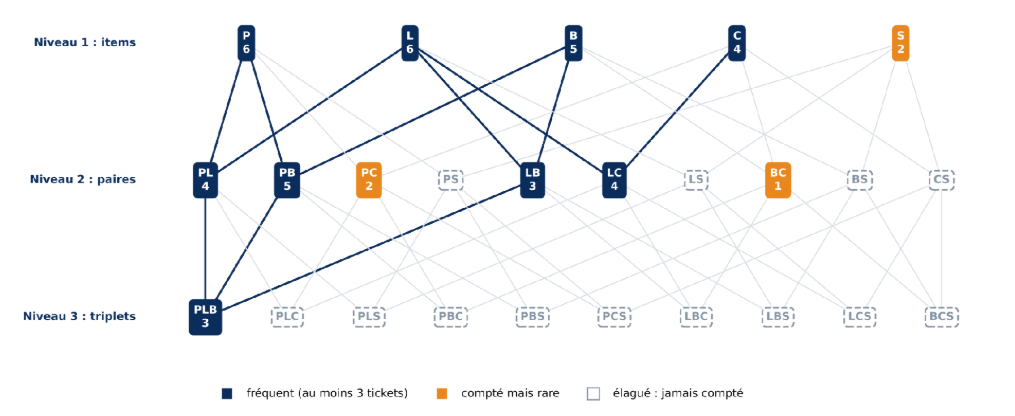

## TD : rayonnages magasin

### Vue d'ensemble

- **Problématique** : Quels produits et quels rayons faut-il rapprocher dans le magasin, parce que les clients les achètent ensemble ?

- **Données** : 2 000 tickets de caisse, 29 produits, 8 rayons = 9 394 lignes, une ligne = 1 produit acheté (possible même ticket) + fichier csv des rayons (1 produit = 1 rayon)

- **Livrable** : Des groupes de produits liés, des rayons à rapprocher, des recommandations de rangement chiffrées

⇒ On part de la matrice produits par tickets, on cherche les itemsets fréquents, puis les règles, puis on remonte du produit au rayon  
Seule la présence d'un produit compte, ni l'ordre, ni la quantité.


### Imports

In [12]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules

### Matrice booléenne

In [11]:
tickets = pd.read_csv("tickets_magasin.csv")

B = pd.crosstab(tickets["id_ticket"],
                tickets["produit"]).astype(bool)

B.shape      # (2000 tickets, 29 produits)

frequence = B.mean().sort_values(ascending=False)
# frequence = support de chaque produit

display(frequence)

produit
Eau                0.6100
Lait               0.3420
Bananes            0.2855
Baguette           0.2840
Yaourts            0.1920
Bière              0.1800
Tomates            0.1750
Salade             0.1700
Pâtes              0.1620
Beurre             0.1590
Oeufs              0.1550
Pommes             0.1515
Céréales           0.1500
Café               0.1450
Confiture          0.1445
Sauce tomate       0.1400
Jus d'orange       0.1395
Fromage râpé       0.1305
Steak haché        0.1250
Chips              0.1160
Soda               0.0970
Cacahuètes         0.0930
Dentifrice         0.0890
Saucisses          0.0885
Papier toilette    0.0815
Shampoing          0.0810
Jambon             0.0795
Croissants         0.0670
Riz                0.0640
dtype: float64

#### Plots // visualisation

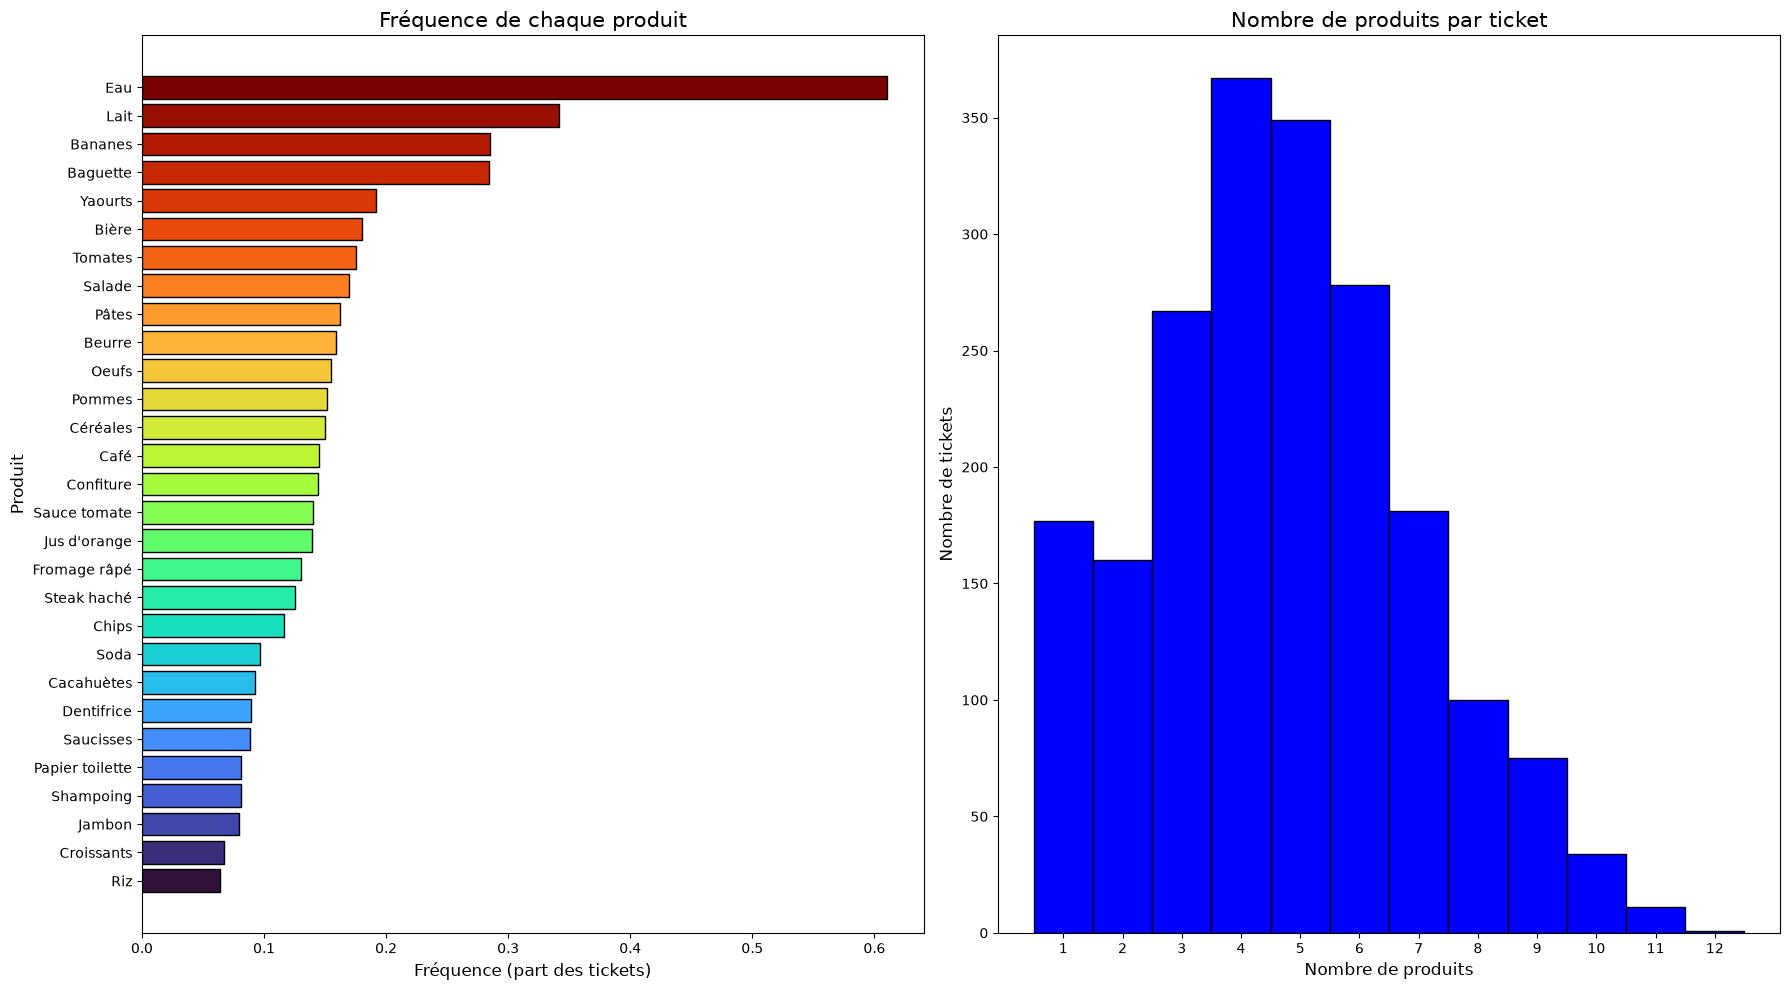

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(18, 10))

# Fréquence par produit
frequence_triee = frequence.sort_values()

couleurs = plt.cm.turbo(
    np.linspace(0, 1, len(frequence_triee))
)

axes[0].barh(
    frequence_triee.index,
    frequence_triee.values,
    color=couleurs,
    edgecolor="black"
)
axes[0].set_title("Fréquence de chaque produit", fontsize=15)
axes[0].set_xlabel("Fréquence (part des tickets)", fontsize=12)
axes[0].set_ylabel("Produit", fontsize=12)
axes[0].tick_params(axis="y", labelsize=10)

# 2. Distribution du nombre de produits par ticket
# B a une ligne par id_ticket : les tickets ayant le même id sont regroupés.
nb_produits_par_ticket = B.sum(axis=1)
bornes = np.arange(
    nb_produits_par_ticket.min() - 0.5,
    nb_produits_par_ticket.max() + 1.5,
    1
)

# Nombre de produits par ticket
axes[1].hist(
    nb_produits_par_ticket,
    bins=bornes,
    color="blue",
    edgecolor="black"
)
axes[1].set_title("Nombre de produits par ticket", fontsize=15)
axes[1].set_xlabel("Nombre de produits", fontsize=12)
axes[1].set_ylabel("Nombre de tickets", fontsize=12)
axes[1].set_xticks(range(
    int(nb_produits_par_ticket.min()),
    int(nb_produits_par_ticket.max()) + 1
))
axes[1].tick_params(labelsize=10)

plt.tight_layout()
plt.show()

Un produit présent dans 61 % des tickets se retrouvera dans presque toutes les règles.

### Algo Apriori

In [65]:
freq_itemsets = apriori(B, min_support=0.03,
             use_colnames=True)
# min_support = seuil min de frequence voulu, ici 3 %

freq_itemsets["nbre_items"] = freq_itemsets["itemsets"].apply(len)

pour visualiser sous un dataframe

In [41]:
itemsets_size = freq_itemsets.groupby("nbre_items").size().reset_index(name="nbre_itemSets")

total = pd.DataFrame([{
    "nbre_items": "Total",
    "nbre_itemSets": itemsets_size["nbre_itemSets"].sum()
}])

itemsets_size = pd.concat([itemsets_size, total], ignore_index=True)


display(itemsets_size)

,nbre_items,nbre_itemSets
0,1,29
1,2,112
2,3,93
3,4,39
4,5,7
5,Total,280


280 itemsets fréquents, dont 251 contiennent au moins deux produits et décrivent de vraies associations.  
Le plus gros groupe compte 5 produits.

### Générer les règles d'association

In [66]:
regles = association_rules(freq_itemsets,
                           metric="confidence",
                           min_threshold=0.5)
# min_treshold = seuil de confiance à 50 %

len(regles) # 604 règles

# display(regles)

604

604 règles ne se lisent pas. On filtre et on regroupe : d'abord les paires de produits, ensuite les paniers types.

`association_rules` : cacule les supports d'antécédent et de conséquent + confiance + lift + pleins d'autres trucs ^^

### Les paires les plus liées

In [67]:
# Garder seulement les itemsets de deux produits
paires = freq_itemsets[freq_itemsets["nbre_items"] == 2].copy()

# Séparer les deux produits de chaque paire
paires["produit_1"] = paires["itemsets"].apply(lambda x: sorted(x)[0])
paires["produit_2"] = paires["itemsets"].apply(lambda x: sorted(x)[1])

# Support de chaque produit seul
support_produits = B.mean()

support_1 = paires["produit_1"].map(support_produits)
support_2 = paires["produit_2"].map(support_produits)

# Mesures d'association
paires["lift"] = paires["support"] / (support_1 * support_2)
paires["confiance_1_vers_2 (%)"] = (
    100 * paires["support"] / support_1
)
paires["confiance_2_vers_1 (%)"] = (
    100 * paires["support"] / support_2
)
paires["nb_tickets"] = (paires["support"] * len(B)).round().astype(int)

# Tableau des 10 paires les plus associées
table_paires = paires[
    [
        "produit_1",
        "produit_2",
        "nb_tickets",
        "support",
        "confiance_1_vers_2 (%)",
        "confiance_2_vers_1 (%)",
        "lift",
    ]
].sort_values("lift", ascending=False).head(10)

table_paires["support"] = table_paires["support"] * 100

display(table_paires.round(2))

,produit_1,produit_2,nb_tickets,support,confiance_1_vers_2 (%),confiance_2_vers_1 (%),lift
95,Dentifrice,Shampoing,142,7.10,79.78,87.65,9.85
131,Papier toilette,Shampoing,130,6.50,79.75,80.25,9.85
94,Dentifrice,Papier toilette,141,7.05,79.21,86.50,9.72
75,Cacahuètes,Chips,159,7.95,85.48,68.53,7.37
132,Pâtes,Sauce tomate,264,13.20,81.48,94.29,5.82
114,Fromage râpé,Pâtes,246,12.30,94.25,75.93,5.82
115,Fromage râpé,Sauce tomate,207,10.35,79.31,73.93,5.67
62,Beurre,Confiture,231,11.55,72.64,79.93,5.03
67,Bière,Chips,206,10.30,57.22,88.79,4.93
84,Confiture,Croissants,95,4.75,32.87,70.90,4.91


Le lift est le même dans les deux sens, pas la confiance : 71 % des tickets avec des croissants contiennent de la confiture, mais seulement 33 % des tickets avec de la confiture contiennent des croissants.  

Un lift supérieur à 1 indique que les deux produits apparaissent ensemble plus souvent que si leurs achats étaient indépendants

### Le piege d'un item présent dans tde nombreux tickets, ici l'eau

In [89]:
masque_eau = (
    paires["produit_1"].str.casefold().eq("eau")
    | paires["produit_2"].str.casefold().eq("eau")
)

associations_eau = (
    paires.loc[masque_eau, [
        "produit_1",
        "produit_2",
        "nb_tickets",
        "confiance_1_vers_2 (%)",
        "confiance_2_vers_1 (%)",
        "lift",
    ]]
    .sort_values("lift", ascending=False)
)

eau_conf_60 = associations_eau[
    (associations_eau["confiance_1_vers_2 (%)"] > 60)
    | (associations_eau["confiance_2_vers_1 (%)"] > 60)
].sort_values("lift", ascending=False)

display(eau_conf_60.round(2))


,produit_1,produit_2,nb_tickets,confiance_1_vers_2 (%),confiance_2_vers_1 (%),lift
108,Eau,Shampoing,107,8.77,66.05,1.08
76,Cacahuètes,Eau,120,64.52,9.84,1.06
35,Baguette,Eau,365,64.26,29.92,1.05
64,Beurre,Eau,204,64.15,16.72,1.05
104,Eau,Riz,82,6.72,64.06,1.05
82,Chips,Eau,148,63.79,12.13,1.05
101,Eau,Papier toilette,103,8.44,63.19,1.04
80,Café,Eau,182,62.76,14.92,1.03
107,Eau,Saucisses,111,9.10,62.71,1.03
68,Bière,Eau,225,62.50,18.44,1.02


Une confiance d'environ 65 % semble forte, mais l'eau est dans 61 % de tous les tickets.  

⇒ Un produit omniprésent a une bonne confiance avec n'importe quoi, et un lift voisin de 1.  
On trie par lift, pas par confiance, et on écarte les produits omniprésents.

In [90]:
# Garder les paires contenant Eau
paires_eau = paires.loc[
    paires["produit_1"].eq("Eau") | paires["produit_2"].eq("Eau")
].copy()

# Réorienter chaque paire pour que la conséquence soit Eau
eau_est_produit_1 = paires_eau["produit_1"].eq("Eau")

paires_eau["Antécédent"] = paires_eau["produit_2"].where(
    eau_est_produit_1, paires_eau["produit_1"]
)
paires_eau["Confiance (%)"] = paires_eau["confiance_2_vers_1 (%)"].where(
    eau_est_produit_1, paires_eau["confiance_1_vers_2 (%)"]
)
paires_eau["Conséquent"] = "Eau"

# Trier par lift et afficher les 5 premières associations
table_eau = (
    paires_eau.loc[paires_eau["lift"] > 1, [
        "Antécédent",
        "Conséquent",
        "Confiance (%)",
        "lift",
    ]]
    .sort_values("lift", ascending=False)
    .head(5)
)

display(table_eau.round(2))

,Antécédent,Conséquent,Confiance (%),lift
108,Shampoing,Eau,66.05,1.08
76,Cacahuètes,Eau,64.52,1.06
35,Baguette,Eau,64.26,1.05
64,Beurre,Eau,64.15,1.05
104,Riz,Eau,64.06,1.05


## SLIDE 45 et code ci dessous = plot final ? (slide 40)

In [ ]:
supports_pct = [2, 3, 4, 5, 6, 8, 10, 15]

itemsets_par_support = {}
nb_itemsets = []
nb_regles = []

for support_pct in supports_pct:
    itemsets = apriori(
        B,
        min_support=support_pct / 100,
        use_colnames=True
    )
    regles = association_rules(
        itemsets,
        metric="confidence",
        min_threshold=0.5
    )

    itemsets_par_support[support_pct] = itemsets
    nb_itemsets.append(len(itemsets))
    nb_regles.append(len(regles))

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(18, 5),
)

# Nombre d'itemsets fréquents
ax1.plot(supports_pct, nb_itemsets, marker="o", color="#173f73")
ax1.axvline(3, color="slategray", linestyle="--")
ax1.set_title("Itemsets fréquents")
ax1.set_xlabel("Support minimal (%)")
ax1.set_ylabel("Nombre d'itemsets")

# Nombre de règles d'association
ax2.plot(supports_pct, nb_regles, marker="o", color="#f58213")
ax2.axvline(3, color="slategray", linestyle="--")
ax2.set_title("Règles (confiance minimale 50 %)")
ax2.set_xlabel("Support minimal (%)")
ax2.set_ylabel("Nombre de règles")

for ax in (ax1, ax2):
    ax.set_xticks(supports_pct)

plt.tight_layout()
plt.show()